# K-Nearest Neighbors (KNN) — Clasificador

**Repositorio:** `autodidact/classification/knn/`

---

## 1. Idea General e Intuición

KNN es un algoritmo **supervisado** y **perezoso** (*lazy learner*): no construye un modelo explícito durante el entrenamiento; memoriza todo el dataset. Al predecir, busca los *K* puntos más cercanos y asigna la clase por votación mayoritaria.

**Proceso:**
1. Calcular distancia entre el punto de consulta y *todos* los puntos del training set.
2. Seleccionar los *K* puntos con menor distancia.
3. Asignar la clase más frecuente entre esos *K* vecinos.

## 2. Fundamento Matemático

### 2.1 Métricas de Distancia

**Distancia Euclidiana** ($p=2$):
$$d(x, x') = \sqrt{\sum_{i=1}^{n} (x_i - x'_i)^2}$$

**Distancia Manhattan** ($p=1$):
$$d(x, x') = \sum_{i=1}^{n} |x_i - x'_i|$$

**Distancia Minkowski** (generalización):
$$d(x, x') = \left(\sum_{i=1}^{n} |x_i - x'_i|^p\right)^{\frac{1}{p}}$$

Donde $x, x'$ son dos puntos, $n$ es el número de features y $p$ controla el tipo de norma.

### 2.2 Regla de Decisión

Dado un punto de consulta $x_q$ y sus $K$ vecinos $\mathcal{N}_K(x_q)$:

$$\hat{y} = \underset{c}{\text{argmax}} \sum_{x_i \in \mathcal{N}_K(x_q)} \mathbb{1}[y_i = c]$$

### 2.3 KNN Ponderado por Distancia

$$\hat{y} = \underset{c}{\text{argmax}} \sum_{x_i \in \mathcal{N}_K(x_q)} \frac{1}{d(x_q, x_i)^2} \cdot \mathbb{1}[y_i = c]$$

Reduce el sesgo de vecinos lejanos.

## 3. ¿Cuándo Usarlo y Cuándo NO?

### ✅ Úsalo cuando:
- Dataset **pequeño o mediano** (≤ 100k muestras).
- Fronteras de decisión **complejas e irregulares**.
- Necesitas un **baseline rápido**.
- Pocos outliers y features bien escaladas.

### ❌ NO lo uses cuando:
- Dataset **muy grande** (predicción O(n·d) no escala).
- Muchas **dimensiones** (maldición de la dimensionalidad).
- Necesitas **predicciones en tiempo real** con baja latencia.
- Hay muchos **outliers** o ruido.

## 4. Métricas de Evaluación

| Métrica | Fórmula | Cuándo usarla |
|---|---|---|
| **Accuracy** | $\frac{TP+TN}{TP+TN+FP+FN}$ | Clases balanceadas |
| **Precision** | $\frac{TP}{TP+FP}$ | Coste alto de falsos positivos |
| **Recall** | $\frac{TP}{TP+FN}$ | Coste alto de falsos negativos |
| **F1-Score** | $\frac{2 \cdot P \cdot R}{P+R}$ | Clases desbalanceadas |
| **ROC-AUC** | Área bajo curva ROC | Comparar modelos |

**Nota:** Con $K=1$, el error de entrenamiento es 0 (sobreajuste). El error de **validación/test** es la métrica relevante.

## 5. Problemas y Casos Raros

### 5.1 Maldición de la Dimensionalidad
En alta dimensión todos los puntos tienden a estar equidistantes:
$$\lim_{d \to \infty} \frac{d_{\max} - d_{\min}}{d_{\min}} \to 0$$
**Solución:** PCA o selección de features antes de KNN.

### 5.2 Sensibilidad al Escalado
Features con rango [0,1000] dominarán sobre features con rango [0,1].  
**Solución:** Siempre usar `StandardScaler` o `MinMaxScaler`.

### 5.3 Empate en Votación
Con $K$ par puede haber empates. Usar **K impar** para clasificación binaria.

### 5.4 Extremos de K
- $K=1$: Sobreajuste, muy sensible a outliers.
- $K=n$: Infraajuste, predice siempre la clase mayoritaria.

## 6. Mejora de Resultados

| Parámetro | Efecto |
|---|---|
| `n_neighbors` (K) | ↑K → menos varianza, más sesgo |
| `weights='distance'` | Reduce efecto de vecinos lejanos |
| `metric` | `euclidean`, `manhattan`, `minkowski` |
| `algorithm` | `ball_tree` / `kd_tree` más rápidos que `brute` |

**Pipeline recomendado:** `StandardScaler → PCA (opcional) → KNN`

In [1]:
# =============================================================================
# SETUP: Importaciones y configuración global
# =============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris, load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, roc_auc_score, RocCurveDisplay
)
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from matplotlib.colors import ListedColormap

import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-darkgrid')
SEED = 42
print('✅ Librerías cargadas correctamente.')

✅ Librerías cargadas correctamente.


---
## 7. Implementación Básica — Dataset Iris

In [2]:
# =============================================================================
# CARGA DEL DATASET IRIS
# =============================================================================
iris = load_iris(as_frame=True)
X, y = iris.data, iris.target
df = iris.frame
df['species'] = pd.Categorical.from_codes(y, iris.target_names)

print(f'Shape: {X.shape} | Clases: {iris.target_names}')
print(f'\nDistribución de clases:\n{df["species"].value_counts()}')
df.head()

Shape: (150, 4) | Clases: ['setosa' 'versicolor' 'virginica']

Distribución de clases:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,species
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


In [3]:
# =============================================================================
# PIPELINE: StandardScaler + KNN
# Se usa Pipeline para evitar data leakage: el scaler se ajusta SOLO
# en los datos de entrenamiento, nunca ve el fold de validación.
# =============================================================================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)

pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier(n_neighbors=5, weights='uniform', metric='euclidean'))
])

pipeline.fit(X_train, y_train)
y_pred = pipeline.predict(X_test)

print(f'Accuracy en Test: {accuracy_score(y_test, y_pred):.4f}')
print('\nReporte de Clasificación:')
print(classification_report(y_test, y_pred, target_names=iris.target_names))

Accuracy en Test: 0.9333

Reporte de Clasificación:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



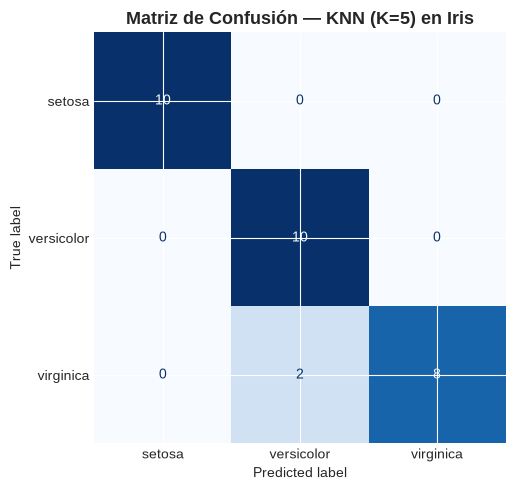

In [4]:
# =============================================================================
# VISUALIZACIÓN 1: Matriz de Confusión
# =============================================================================
fig, ax = plt.subplots(figsize=(6, 5))
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=iris.target_names).plot(
    ax=ax, colorbar=False, cmap='Blues'
)
ax.set_title('Matriz de Confusión — KNN (K=5) en Iris', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

Mejor K: 5 | CV Accuracy: 0.9667


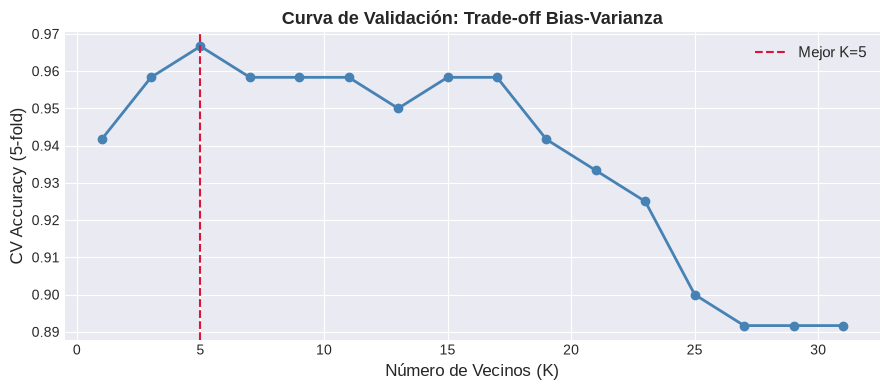

In [5]:
# =============================================================================
# BÚSQUEDA DEL K ÓPTIMO — Curva Bias-Varianza
# Barremos K impares (para evitar empates) y medimos accuracy con CV 5-fold
# =============================================================================
k_values = list(range(1, 32, 2))
cv_scores = []

for k in k_values:
    pipe_k = Pipeline([
        ('scaler', StandardScaler()),
        ('knn', KNeighborsClassifier(n_neighbors=k))
    ])
    scores = cross_val_score(pipe_k, X_train, y_train, cv=5, scoring='accuracy')
    cv_scores.append(scores.mean())

best_k = k_values[int(np.argmax(cv_scores))]
print(f'Mejor K: {best_k} | CV Accuracy: {max(cv_scores):.4f}')

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(k_values, cv_scores, 'o-', color='steelblue', linewidth=2, markersize=6)
ax.axvline(best_k, color='crimson', linestyle='--', label=f'Mejor K={best_k}')
ax.set_xlabel('Número de Vecinos (K)', fontsize=12)
ax.set_ylabel('CV Accuracy (5-fold)', fontsize=12)
ax.set_title('Curva de Validación: Trade-off Bias-Varianza', fontsize=13, fontweight='bold')
ax.legend(fontsize=11)
plt.tight_layout()
plt.show()

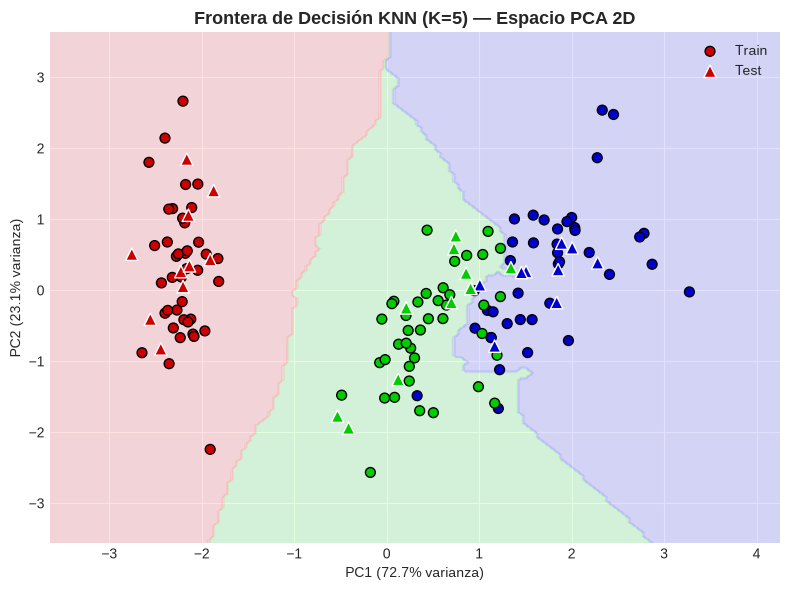

In [6]:
# =============================================================================
# FRONTERA DE DECISIÓN en 2D (via PCA)
# PCA reduce las 4 features a 2 dimensiones para poder visualizar.
# =============================================================================
scaler_vis = StandardScaler()
X_train_sc = scaler_vis.fit_transform(X_train)
X_test_sc  = scaler_vis.transform(X_test)

pca = PCA(n_components=2, random_state=SEED)
X_train_2d = pca.fit_transform(X_train_sc)
X_test_2d  = pca.transform(X_test_sc)

knn_2d = KNeighborsClassifier(n_neighbors=best_k)
knn_2d.fit(X_train_2d, y_train)

# Malla para pintar regiones de decisión
h = 0.05
x_min, x_max = X_train_2d[:,0].min()-1, X_train_2d[:,0].max()+1
y_min, y_max = X_train_2d[:,1].min()-1, X_train_2d[:,1].max()+1
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
Z = knn_2d.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

cmap_bg  = ListedColormap(['#FFAAAA','#AAFFAA','#AAAAFF'])
cmap_pts = ListedColormap(['#CC0000','#00CC00','#0000CC'])

fig, ax = plt.subplots(figsize=(8, 6))
ax.contourf(xx, yy, Z, alpha=0.35, cmap=cmap_bg)
ax.scatter(X_train_2d[:,0], X_train_2d[:,1], c=y_train, cmap=cmap_pts,
           edgecolors='k', s=50, label='Train')
ax.scatter(X_test_2d[:,0], X_test_2d[:,1], c=y_test, cmap=cmap_pts,
           edgecolors='white', s=80, marker='^', label='Test')
ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% varianza)')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% varianza)')
ax.set_title(f'Frontera de Decisión KNN (K={best_k}) — Espacio PCA 2D',
             fontsize=13, fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

---
## 8. Caso Avanzado — Breast Cancer (Binario) con GridSearchCV

In [7]:
# =============================================================================
# BREAST CANCER — GridSearchCV para optimización exhaustiva
# 30 features numéricas, 2 clases (maligno/benigno)
# =============================================================================
bc = load_breast_cancer(as_frame=True)
X_bc, y_bc = bc.data, bc.target

X_tr, X_te, y_tr, y_te = train_test_split(
    X_bc, y_bc, test_size=0.2, random_state=SEED, stratify=y_bc
)

param_grid = {
    'knn__n_neighbors': [3, 5, 7, 9, 11, 15, 21],
    'knn__weights':     ['uniform', 'distance'],
    'knn__metric':      ['euclidean', 'manhattan']
}

pipe_bc = Pipeline([('scaler', StandardScaler()), ('knn', KNeighborsClassifier())])

# ROC-AUC como métrica: más robusta que accuracy para clases desbalanceadas
grid_search = GridSearchCV(pipe_bc, param_grid, cv=5, scoring='roc_auc', n_jobs=-1)
grid_search.fit(X_tr, y_tr)

print(f'Mejores parámetros: {grid_search.best_params_}')
print(f'Mejor ROC-AUC (CV): {grid_search.best_score_:.4f}')

best_model   = grid_search.best_estimator_
y_pred_bc    = best_model.predict(X_te)
y_proba_bc   = best_model.predict_proba(X_te)[:, 1]

print(f'\nROC-AUC en Test: {roc_auc_score(y_te, y_proba_bc):.4f}')
print(classification_report(y_te, y_pred_bc, target_names=bc.target_names))

Mejores parámetros: {'knn__metric': 'euclidean', 'knn__n_neighbors': 9, 'knn__weights': 'distance'}
Mejor ROC-AUC (CV): 0.9930

ROC-AUC en Test: 0.9934
              precision    recall  f1-score   support

   malignant       1.00      0.93      0.96        42
      benign       0.96      1.00      0.98        72

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114



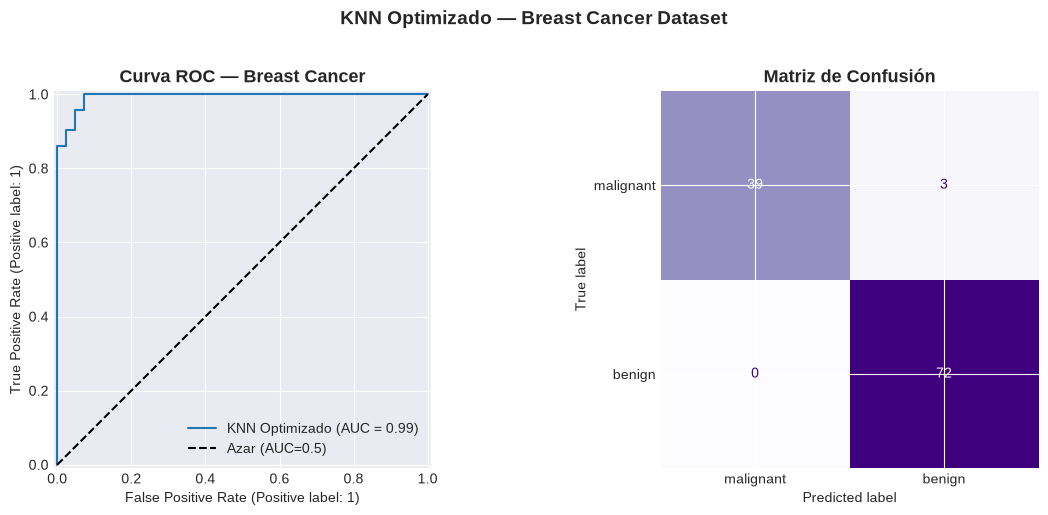

In [8]:
# =============================================================================
# VISUALIZACIÓN 2: Curva ROC + Matriz de Confusión
# =============================================================================
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

RocCurveDisplay.from_estimator(best_model, X_te, y_te, ax=axes[0], name='KNN Optimizado')
axes[0].plot([0,1],[0,1],'k--', label='Azar (AUC=0.5)')
axes[0].set_title('Curva ROC — Breast Cancer', fontsize=13, fontweight='bold')
axes[0].legend()

ConfusionMatrixDisplay(confusion_matrix(y_te, y_pred_bc),
                       display_labels=bc.target_names).plot(
    ax=axes[1], colorbar=False, cmap='Purples'
)
axes[1].set_title('Matriz de Confusión', fontsize=13, fontweight='bold')

plt.suptitle('KNN Optimizado — Breast Cancer Dataset',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

---
## 9. Impacto del Escalado

Sin Escalar            → ROC-AUC: 0.9596 ± 0.0121
Con StandardScaler     → ROC-AUC: 0.9916 ± 0.0067


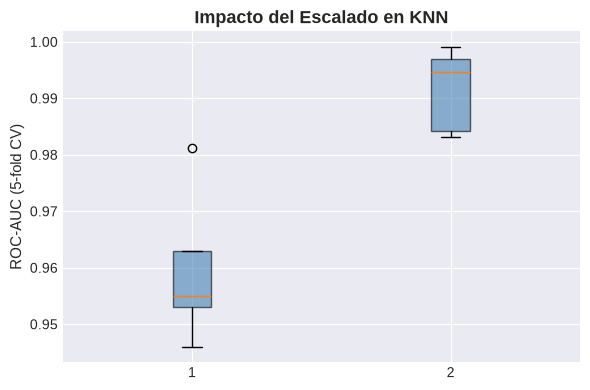

In [10]:
# =============================================================================
# COMPARACIÓN: Sin Scaler vs Con StandardScaler
# Una de las fuentes de error más comunes al usar KNN
# =============================================================================
results = {}
for scaled, label in [(False, 'Sin Escalar'), (True, 'Con StandardScaler')]:
    if scaled:
        pipe_tmp = Pipeline([('scaler', StandardScaler()),
                             ('knn', KNeighborsClassifier(n_neighbors=5))])
    else:
        pipe_tmp = Pipeline([('knn', KNeighborsClassifier(n_neighbors=5))])

    scores = cross_val_score(pipe_tmp, X_bc, y_bc, cv=5, scoring='roc_auc')
    results[label] = scores
    print(f'{label:22s} → ROC-AUC: {scores.mean():.4f} ± {scores.std():.4f}')

fig, ax = plt.subplots(figsize=(6, 4))
ax.boxplot(results.values(), label=results.keys(), patch_artist=True,
           boxprops=dict(facecolor='steelblue', alpha=0.6))
ax.set_ylabel('ROC-AUC (5-fold CV)', fontsize=11)
ax.set_title('Impacto del Escalado en KNN', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

---
## 10. Resumen y Checklist

| Aspecto | Detalle |
|---|---|
| **Tipo** | Lazy learner, no paramétrico |
| **Entrenamiento** | O(1) — solo memoriza |
| **Predicción** | O(n·d) — costoso en datasets grandes |
| **Hiperparámetro clave** | K (número de vecinos) |
| **Preprocesamiento obligatorio** | Escalado de features |
| **Fortaleza** | Sin supuestos distribucionales |
| **Debilidad** | Lento, sensible a dimensionalidad |

### ✅ Checklist antes de usar KNN:
- [ ] ¿Escalé las features? (**CRÍTICO**)
- [ ] ¿Usé K impar para clasificación binaria?
- [ ] ¿Exploré `weights='distance'`?
- [ ] ¿El dataset cabe en memoria?
- [ ] ¿Consideré PCA si d > 20?

---
*Próximo notebook: Naive Bayes Classifier*